# 11 · Combined ranking evaluation and demo database
CPU runtime. Run after notebooks 08, 09 and 10.

**Limitation:** no recording has *both* a human singing-quality rating and a commercial-success label. Candidates are
therefore built by pairing an independent held-out MOS clip with an independent held-out Spotify track. The evaluation
shows how the weighting trades the two criteria off and how well the model-based ranking reproduces a ranking built
from the true labels. It cannot show real-world A&R value.

- **Weight sensitivity** (MOS-only, 70/30 … 30/70, hit-only) for batch sizes 10/50/100:
  - Precision of the top-10% selection for "good singer", "hit" and "both".
  - Spearman between the predicted score and the same-weight score computed from the true labels.
  - Kendall τ and top-k overlap against the 60/40 ranking.
- **Transposition:** rank effect of pitch shifting (uses `mos_transpose_preds.csv` from notebook 09).
- **Selection rule:** `k = ceil(0.1 · n)` on unrounded scores, ties broken by the higher predicted MOS
  (the same rule as `app.py`).
- **Demo database** for the webapp, built only from held-out test items of both models.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import os, math, zipfile
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr, kendalltau

OUT = "/content/drive/MyDrive/szakdolgozat/v2"
RES = f"{OUT}/results"
W_MOS = [1.0, 0.7, 0.6, 0.5, 0.4, 0.3, 0.0]     # weight on MOS; hit weight = 1 - w
BATCH_SIZES = [10, 50, 100]
N_BATCHES = 2000
GOOD_MOS = 4.0               # "good singer" = true MOS >= 4.0
SEED = 42
MOS_MODEL = ""               # "" = final model (no augmentation), "_aug" = ablation trained with augmentation

mos = pd.read_csv(f"{OUT}/mos_test_preds.csv")
mos["pred"] = mos["pred" + MOS_MODEL]
hit = pd.read_csv(f"{OUT}/hit_test_preds.csv")
print(len(mos), "MOS test clips,", len(hit), "hit test tracks")
print("base rates: good singer", round((mos.mos >= GOOD_MOS).mean(), 3), "| hit", round(hit.target.mean(), 3))

1194 MOS test clips, 2367 hit test tracks
base rates: good singer 0.408 | hit 0.515


In [3]:
def overall(w, mos_pred, hit_prob):
    """Same formula as app.py: w * MOS/5 + (1 - w) * P(hit)."""
    return w * np.clip(mos_pred, 1, 5) / 5 + (1 - w) * hit_prob

def select_top(score, mos_pred):
    """Top ceil(10%) by score; ties -> higher predicted MOS."""
    k = math.ceil(0.1 * len(score))
    return np.lexsort((-mos_pred, -score))[:k]

## Weight sensitivity

In [4]:
rng = np.random.default_rng(SEED)
rows = []
for n in BATCH_SIZES:
    for b in range(N_BATCHES):
        m = mos.iloc[rng.choice(len(mos), n, replace=False)]
        h = hit.iloc[rng.choice(len(hit), n, replace=False)]
        mp, mt, hp, ht = m.pred.values, m.mos.values, h.prob.values, h.target.values
        good, is_hit = mt >= GOOD_MOS, ht == 1
        ref = overall(0.6, mp, hp)
        ref_top = set(select_top(ref, mp))
        for w in W_MOS:
            s = overall(w, mp, hp)
            top = select_top(s, mp)
            rows.append({"batch_size": n, "w_mos": w,
                         "prec_good_singer": good[top].mean(), "prec_hit": is_hit[top].mean(),
                         "prec_both": (good & is_hit)[top].mean(),
                         "spearman_vs_true_score": spearmanr(s, overall(w, mt, ht))[0],
                         "kendall_vs_60_40": kendalltau(s, ref)[0],
                         "topk_overlap_vs_60_40": len(ref_top & set(top)) / len(top)})
sens = pd.DataFrame(rows)

def mean_ci(x):
    return f"{x.mean():.3f} ± {1.96 * x.std() / np.sqrt(len(x)):.3f}"

table = sens.groupby(["batch_size", "w_mos"]).agg(mean_ci).sort_index(ascending=[True, False])
table.to_csv(f"{RES}/table_ranking_weight_sensitivity.csv"); table

/tmp/ipykernel_1431/1524774908.py:17: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "spearman_vs_true_score": spearmanr(s, overall(w, mt, ht))[0],


prec_good_singer       prec_hit      prec_both  \
batch_size w_mos                                                  
10         1.0      0.789 ± 0.018  0.515 ± 0.022  0.406 ± 0.022   
           0.7      0.696 ± 0.020  0.846 ± 0.016  0.587 ± 0.022   
           0.6      0.680 ± 0.020  0.867 ± 0.015  0.585 ± 0.022   
           0.5      0.652 ± 0.021  0.878 ± 0.014  0.567 ± 0.022   
           0.4      0.625 ± 0.021  0.884 ± 0.014  0.550 ± 0.022   
           0.3      0.596 ± 0.022  0.886 ± 0.014  0.528 ± 0.022   
           0.0      0.422 ± 0.022  0.894 ± 0.013  0.373 ± 0.021   
50         1.0      0.808 ± 0.008  0.512 ± 0.010  0.416 ± 0.010   
           0.7      0.727 ± 0.009  0.854 ± 0.007  0.619 ± 0.010   
           0.6      0.707 ± 0.009  0.873 ± 0.007  0.617 ± 0.010   
           0.5      0.685 ± 0.009  0.886 ± 0.006  0.606 ± 0.010   
           0.4      0.658 ± 0.010  0.894 ± 0.006  0.587 ± 0.010   
           0.3      0.617 ± 0.010  0.902 ± 0.006  0.556 ± 0.010   
           0.0      0.409 ± 0.010  0.909 ± 0.006  0.373 ± 0.009   
100        1.0      0.816 ± 0.005  0.516 ± 0.007  0.422 ± 0.007   
           0.7      0.730 ± 0.006  0.859 ± 0.005  0.624 ± 0.007   
           0.6      0.711 ± 0.006  0.874 ± 0.004  0.618 ± 0.007   
           0.5      0.690 ± 0.006  0.885 ± 0.004  0.608 ± 0.007   
           0.4      0.660 ± 0.007  0.894 ± 0.004  0.588 ± 0.007   
           0.3      0.623 ± 0.007  0.903 ± 0.004  0.560 ± 0.007   
           0.0      0.410 ± 0.007  0.904 ± 0.004  0.371 ± 0.007   

                 spearman_vs_true_score kendall_vs_60_40 topk_overlap_vs_60_40  
batch_size w_mos                                                                
10         1.0            0.533 ± 0.012    0.377 ± 0.010         0.416 ± 0.022  
           0.7            0.628 ± 0.010    0.902 ± 0.003         0.913 ± 0.012  
           0.6            0.640 ± 0.009    1.000 ± 0.000         1.000 ± 0.000  
           0.5            0.640 ± 0.009    0.925 ± 0.003         0.897 ± 0.013  
           0.4            0.634 ± 0.009    0.863 ± 0.004         0.795 ± 0.018  
           0.3            0.621 ± 0.010    0.804 ± 0.005         0.678 ± 0.020  
           0.0            0.662 ± 0.008    0.623 ± 0.007         0.322 ± 0.020  
50         1.0            0.562 ± 0.005    0.371 ± 0.004         0.443 ± 0.009  
           0.7            0.661 ± 0.004    0.902 ± 0.001         0.902 ± 0.005  
           0.6            0.671 ± 0.004    1.000 ± 0.000         1.000 ± 0.000  
           0.5            0.671 ± 0.004    0.926 ± 0.001         0.901 ± 0.005  
           0.4            0.665 ± 0.004    0.865 ± 0.001         0.805 ± 0.006  
           0.3            0.653 ± 0.004    0.808 ± 0.002         0.703 ± 0.007  
           0.0            0.690 ± 0.003    0.626 ± 0.002         0.339 ± 0.008  
100        1.0            0.564 ± 0.003    0.374 ± 0.003         0.450 ± 0.006  
           0.7            0.669 ± 0.003    0.903 ± 0.001         0.906 ± 0.003  
           0.6            0.679 ± 0.003    1.000 ± 0.000         1.000 ± 0.000  
           0.5            0.678 ± 0.003    0.927 ± 0.000         0.903 ± 0.003  
           0.4            0.672 ± 0.002    0.865 ± 0.001         0.812 ± 0.004  
           0.3            0.660 ± 0.002    0.808 ± 0.001         0.713 ± 0.005  
           0.0            0.693 ± 0.002    0.627 ± 0.002         0.342 ± 0.006

random selection (expected precision): {'prec_good_singer': np.float64(0.408), 'prec_hit': np.float64(0.515), 'prec_both': np.float64(0.21)}
SD of MOS term 0.080 | SD of hit term 0.142 | effective MOS share 0.36 (nominal 0.60)


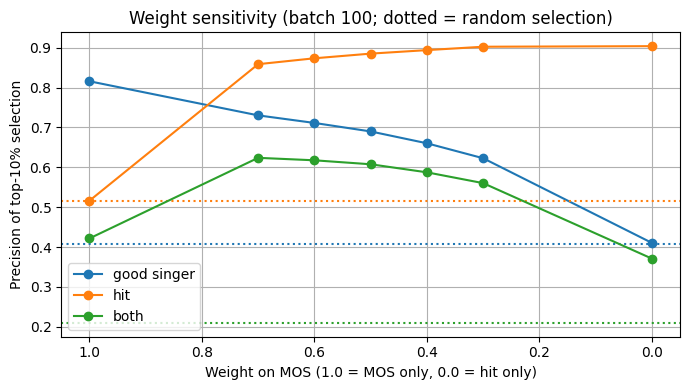

In [5]:
rand = {"prec_good_singer": (mos.mos >= GOOD_MOS).mean(), "prec_hit": hit.target.mean(),
        "prec_both": (mos.mos >= GOOD_MOS).mean() * hit.target.mean()}
print("random selection (expected precision):", {k: round(v, 3) for k, v in rand.items()})

# Nominal 60/40 vs effective influence: a term's influence on the ranking is its spread across candidates,
# and predicted MOS is squeezed toward the middle while hit probabilities span 0-1.
a, b = 0.6 * np.clip(mos.pred, 1, 5) / 5, 0.4 * hit.prob
print(f"SD of MOS term {a.std():.3f} | SD of hit term {b.std():.3f} | "
      f"effective MOS share {a.std() / (a.std() + b.std()):.2f} (nominal 0.60)")

g = sens[sens.batch_size == 100].groupby("w_mos").mean().sort_index(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4))
for col, label in [("prec_good_singer", "good singer"), ("prec_hit", "hit"), ("prec_both", "both")]:
    line, = ax.plot(g.index, g[col], "o-", label=f"{label}")
    ax.axhline(rand[col], ls=":", c=line.get_color())
ax.invert_xaxis()
ax.set_xlabel("Weight on MOS (1.0 = MOS only, 0.0 = hit only)"); ax.set_ylabel("Precision of top-10% selection")
ax.set_title("Weight sensitivity (batch 100; dotted = random selection)"); ax.legend(); ax.grid(True)
plt.tight_layout(); plt.savefig(f"{RES}/fig_ranking_weight_sensitivity.png", dpi=200); plt.show()

## Does transposition change the ranking?
Each transposed clip is paired with one random hit-test track and placed into a batch of 10 with 9 random other
candidates (20 batches per clip and shift). We record how its rank and its selection status change when only the
pitch shift is applied. The hit probability does not depend on the audio, so only the MOS term moves.

In [6]:
TR_CSV = f"{OUT}/mos_transpose_preds.csv"
tr = pd.read_csv(TR_CSV).query("kind == 'shift'").copy()          # real transpositions only, no round trips
tr["pred_shift"] = tr["pred_shift" + MOS_MODEL]
tr = tr.merge(mos[["wav", "pred"]], on="wav")
rng = np.random.default_rng(SEED)
pair_prob = dict(zip(tr.wav.unique(), rng.choice(hit.prob.values, tr.wav.nunique())))
R, N = 20, 10
k = math.ceil(0.1 * N)
rows = []
for r in tr.itertuples():
    hp = pair_prob[r.wav]
    s0, s1 = overall(0.6, r.pred, hp), overall(0.6, r.pred_shift, hp)
    others = overall(0.6, rng.choice(mos.pred.values, (R, N - 1)), rng.choice(hit.prob.values, (R, N - 1)))
    rank0, rank1 = 1 + (others > s0).sum(1), 1 + (others > s1).sum(1)
    rows.append({"shift": r.shift, "abs_delta_score": abs(s1 - s0), "abs_delta_rank": np.abs(rank1 - rank0).mean(),
                 "selection_flip_rate": ((rank0 <= k) != (rank1 <= k)).mean()})
tr_rank = pd.DataFrame(rows).groupby("shift").mean().round(4)
tr_rank.to_csv(f"{RES}/ranking_transposition.csv"); tr_rank

,abs_delta_score,abs_delta_rank,selection_flip_rate
shift,,,
-3,0.1644,2.3701,0.1045
-2,0.1577,2.3025,0.1076
-1,0.1447,2.1655,0.1052
1,0.1593,2.3266,0.1069
2,0.1612,2.3524,0.1022
3,0.1632,2.3793,0.1019


## Demo database for the webapp (held-out items only)
Writes `Artists.csv`, `Tracks.csv`, `StreamingData.csv` (same columns as `streamlit-webapp/data/`) and
`demo_audio.zip`. Artist names are placeholders. The streaming features come from the held-out Spotify
record paired with each clip; they are **not** computed from the audio.

In [7]:
N_DEMO = 200
DEMO = f"{OUT}/demo_db"
os.makedirs(DEMO, exist_ok=True)
rng = np.random.default_rng(SEED)
m = mos.iloc[rng.choice(len(mos), N_DEMO, replace=False)].reset_index(drop=True)
h = hit.iloc[rng.choice(len(hit), N_DEMO, replace=False)].reset_index(drop=True)
ids = np.arange(1, N_DEMO + 1)

pd.DataFrame({"ArtistId": ids, "name": [f"Demo Artist {i:03d}" for i in ids]}).to_csv(f"{DEMO}/Artists.csv", index=False)
pd.DataFrame({"FileName": m.wav, "ArtistId": ids, "TrackId": ids}).to_csv(f"{DEMO}/Tracks.csv", index=False)
sd = h[["danceability", "energy", "key", "loudness", "mode", "speechiness", "acousticness", "instrumentalness",
        "liveness", "valence", "tempo", "duration_ms", "time_signature", "chorus_hit", "sections"]].copy()
sd["TrackId"], sd["StreamingDataId"] = ids, ids
sd.to_csv(f"{DEMO}/StreamingData.csv", index=False)
# ground truth for reference only (not loaded into the DB)
pd.DataFrame({"ArtistId": ids, "wav": m.wav, "true_mos": m.mos, "source": m.source,
              "spotify_uri": h.uri, "true_hit": h.target}).to_csv(f"{DEMO}/demo_truth.csv", index=False)

need = set(m.wav)
with zipfile.ZipFile(f"{OUT}/mos_audio.zip") as src, zipfile.ZipFile(f"{DEMO}/demo_audio.zip", "w") as dst:
    for n in src.namelist():
        if os.path.basename(n) in need:
            dst.writestr(os.path.basename(n), src.read(n))
print("demo DB written to", DEMO)

demo DB written to /content/drive/MyDrive/szakdolgozat/v2/demo_db
